# AIML Project

***

## Project Title

**ARES** -  Adaptive Reinforcement-based Endpoint Security

***

## Project Description

**ARES (Adaptive Reinforcement-based Endpoint Security)** is an intelligent endpoint security system designed to detect and prevent evolving cyber threats. It uses machine learning and adaptive techniques to identify QR-code phishing (quishing). The system analyzes threats in real time and assigns risk levels to potentially harmful activities. ARES can alert users, block malicious content, and continuously improve its detection based on previous threat patterns. The primary focus is on QR-code phishing.

***

## Team Members


| Sl. No. | Name                         | USN          |
|---------|------------------------------|--------------|
| 1       | Aryan S Jain                  | 1RUA25CSE0087 |
| 2       | Ashwin Chandrashekar Naik     | 1RUA25CSE0090 |
| 3       | Ashwin Rajesha Bhat           | 1RUA25CSE0091 |
| 4       | Ashwin Subramaniam            | 1RUA25CSE0092 |

***

## Phase 01: Verification of the modal artifact v2.3

### Step 1.1

Verify the model artifact v2.3

***

In [1]:
# Importing the pandas, joblib, and json libraries
import pandas as pd
import joblib
import json

# Storing the model path, metadata path, and sample dataset path in variables
model_path = "/kaggle/input/models/parkdoyunalias0004/aresv2-3/scikitlearn/v2.3/1/model.joblib"
metadata_path = "/kaggle/input/models/parkdoyunalias0004/ares-metadata/scikitlearn/v3.3/1/metadata.json"
test_data_path = "/kaggle/input/models/parkdoyunalias0004/aresv2-3/scikitlearn/v2.3/1/test_sample_v2_3.csv"

# Load the model artifact
artifact = joblib.load(model_path)

# Extract the trained estimator from the dictionary
model = artifact["model"]

# Load the metadata JSON file in read mode
with open(metadata_path) as file:
    metadata = json.load(file)

# Read the CSV dataset to get the sample inputs
X = pd.read_csv(test_data_path)

# Check if feature order matches training column names
X = X[metadata["feature_names"]]

# Evaluate predictions & probabilities on the sample data
predictions = model.predict(X)
probabilities = model.predict_proba(X)[:, 1]

# Display the formatted output
print(f"Metadata:\n\n{metadata}\n\nPredictions:\n\n{predictions}\n\nProbabilities:\n\n{probabilities}")

Metadata:

{'model_name': 'RandomForestClassifier', 'model_file': 'model.joblib', 'framework': 'scikit-learn', 'sklearn_version': '1.6.1', 'random_seed': 42, 'task': 'binary_classification', 'positive_class': 1, 'feature_names': ['url_length', 'num_dots', 'has_https', 'has_ip', 'num_subdirs', 'num_params', 'suspicious_words', 'special_char_count', 'digits_count', 'entropy'], 'n_features': 10, 'training_samples': 128051, 'dataset_limitations': ['The dataset may not represent the full population or future production data.', 'Class imbalance may make accuracy misleading; balanced accuracy, recall, F1, and average precision should also be considered.', 'The train/test split is a single split; results may vary with a different random seed or cross-validation setup.', 'The model uses only the features available in this dataset and may omit important predictive variables.', 'Predictions should not be used for high-stakes decisions without domain review, fairness checks, and monitoring.']}

Pr

### Step 1.2

Check modal features

***

In [2]:
import joblib

FEATURES = [
    "url_length",
    "num_dots",
    "has_https",
    "has_ip",
    "num_subdirs",
    "num_params",
    "suspicious_words",
    "special_char_count",
    "digits_count",
    "entropy",
]

# Load the bundle
bundle = joblib.load("/kaggle/input/models/parkdoyunalias0004/aresv2-3/scikitlearn/v2.3/1/model.joblib")

# 1. Sanity check: is it a dict with the expected keys?
print("Bundle keys:", list(bundle.keys()) if isinstance(bundle, dict) else type(bundle))

# 2. Pull the saved feature list
saved_features = bundle["features"]

print("\nSaved features:", saved_features)
print("Expected features:", FEATURES)

# 3. Exact-match check (order + names)
if saved_features == FEATURES:
    print("\n✅ Features match EXACTLY (same names, same order).")
else:
    print("\n❌ Features do NOT match.")

    # Show what's different
    missing = [f for f in FEATURES if f not in saved_features]
    extra   = [f for f in saved_features if f not in FEATURES]
    if missing:
        print("  Missing from model :", missing)
    if extra:
        print("  Extra in model     :", extra)

    # Same set, wrong order?
    if set(saved_features) == set(FEATURES) and saved_features != FEATURES:
        print("  ⚠️ Same features but DIFFERENT ORDER:")
        for i, (a, b) in enumerate(zip(saved_features, FEATURES)):
            marker = "✓" if a == b else "✗"
            print(f"    [{i}] model={a:<22} expected={b:<22} {marker}")

# 4. Bonus: does the underlying estimator also agree?
model = bundle["model"]
if hasattr(model, "feature_names_in_"):
    print("\nEstimator.feature_names_in_:", list(model.feature_names_in_))
    print("Matches FEATURES:",
          list(model.feature_names_in_) == FEATURES)
else:
    print("\nEstimator has no feature_names_in_ "
          "(trained on numpy array, not a named DataFrame).")

# 5. n_features_in_ sanity check
print("n_features_in_:", getattr(model, "n_features_in_", "N/A"),
      "| expected:", len(FEATURES))

Bundle keys: ['model', 'features', 'label_mapping']

Saved features: ['url_length', 'num_dots', 'has_https', 'has_ip', 'num_subdirs', 'num_params', 'suspicious_words', 'special_char_count', 'digits_count', 'entropy']
Expected features: ['url_length', 'num_dots', 'has_https', 'has_ip', 'num_subdirs', 'num_params', 'suspicious_words', 'special_char_count', 'digits_count', 'entropy']

✅ Features match EXACTLY (same names, same order).

Estimator.feature_names_in_: ['url_length', 'num_dots', 'has_https', 'has_ip', 'num_subdirs', 'num_params', 'suspicious_words', 'special_char_count', 'digits_count', 'entropy']
Matches FEATURES: True
n_features_in_: 10 | expected: 10


### Step 1.3

Try harder decoding on one QR-Code sample

***

In [3]:
import cv2, numpy as np
from pathlib import Path
import pickle

with open('/kaggle/input/datasets/parkdoyunalias0004/dataset2/qr_codes_29.pickle','rb') as f:
    X = pickle.load(f)
with open('/kaggle/input/datasets/parkdoyunalias0004/dataset2/qr_codes_29_labels.pickle','rb') as f:
    y = pickle.load(f)

img = (X[0].astype(np.uint8)) * 255

# Try with a quiet zone
padded = cv2.copyMakeBorder(img, 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=255)

for scale in [1, 2, 4, 8, 16]:
    big = cv2.resize(padded, None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST)
    data, pts, _ = cv2.QRCodeDetector().detectAndDecode(big)
    print(f"scale={scale:2d}  decoded={data!r}")

# Also try pyzbar as a second opinion (pip install pyzbar)
try:
    from pyzbar.pyzbar import decode
    result = decode(img)
    print("pyzbar:", result)
except Exception as e:
    print("pyzbar not available:", e)

scale= 1  decoded=''
scale= 2  decoded=''
scale= 4  decoded='www.ecslimited.com/environ.cfm'
scale= 8  decoded='www.ecslimited.com/environ.cfm'
scale=16  decoded='www.ecslimited.com/environ.cfm'
pyzbar not available: No module named 'pyzbar'


### Step 1.4

Saving a sample QR-Code PNG image file

***

In [4]:
benign_index = int(np.where(y == 0)[0][0])
phishing_index = int(np.where(y == 1)[0][0])

In [5]:
# Defining a function to save a sample QR Code image
def save_sample_qr_code_image(index, image_name):
    image = (X[index].astype(np.uint8)) * 255

    path = f"/kaggle/working/{image_name}.png"

    cv2.imwrite(path, image)

In [6]:
# Calling the function save_sample_qr_code_image() to generate a sample QR-Code image
save_sample_qr_code_image(benign_index, "sample_benign_qr_code")

In [7]:
# Calling the function save_sample_qr_code_image() to generate a sample QR-Code image
save_sample_qr_code_image(phishing_index, "sample_phishing_qr_code")

In [8]:
import cv2, numpy as np
img = cv2.imread("/kaggle/working/sample_phishing_qr_code.png", cv2.IMREAD_GRAYSCALE)
print("shape/dtype:", img.shape, img.dtype, "| min/max:", img.min(), img.max())

padded = cv2.copyMakeBorder(img, 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=255)
det = cv2.QRCodeDetector()
for s in (1, 2, 4, 6, 8, 10, 16):
    big = cv2.resize(padded, None, fx=s, fy=s, interpolation=cv2.INTER_NEAREST)
    data, _, _ = det.detectAndDecode(big)
    print(f"scale={s:2d}: {data!r}")

shape/dtype: (69, 69) uint8 | min/max: 0 255
scale= 1: ''
scale= 2: ''
scale= 4: 'complexesadiya.com/www/paypal/co/uk/cgi-bin/login_error.php'
scale= 6: 'complexesadiya.com/www/paypal/co/uk/cgi-bin/login_error.php'
scale= 8: 'complexesadiya.com/www/paypal/co/uk/cgi-bin/login_error.php'
scale=10: 'complexesadiya.com/www/paypal/co/uk/cgi-bin/login_error.php'
scale=16: 'complexesadiya.com/www/paypal/co/uk/cgi-bin/login_error.php'


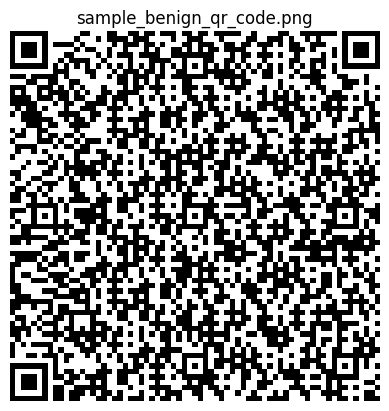

In [9]:
import matplotlib.pyplot as plt
plt.imshow(cv2.imread("/kaggle/working/sample_phishing_qr_code.png", cv2.IMREAD_GRAYSCALE), cmap="gray")
plt.title("sample_benign_qr_code.png")
plt.axis("off")
plt.show()

In [10]:
import cv2, numpy as np

path = "/kaggle/working/sample_benign_qr_code.png"
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
print("shape :", img.shape)
print("dtype :", img.dtype)
print("min/max:", img.min(), img.max())
print("unique :", np.unique(img)[:10], "...", np.unique(img)[-5:])
print("mean  :", img.mean())
print("corners (should be white=255 for a normal QR):")
print(img[:3,:3])
print(img[-3:,-3:])

# Save a copy so you can look at it
cv2.imwrite("/tmp/sample_check.png", img)

# Try decoding at multiple scales, with and without padding
det = cv2.QRCodeDetector()
padded = cv2.copyMakeBorder(img, 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=255)

for tag, arr in [("raw", img), ("padded", padded)]:
    for s in (1, 2, 4, 6, 8, 10, 16):
        big = cv2.resize(arr, None, fx=s, fy=s, interpolation=cv2.INTER_NEAREST)
        data, _, _ = det.detectAndDecode(big)
        print(f"{tag:8s} scale={s:2d}: {data!r}")

shape : (69, 69)
dtype : uint8
min/max: 0 255
unique : [  0 255] ... [  0 255]
mean  : 125.81285444234405
corners (should be white=255 for a normal QR):
[[  0   0   0]
 [  0 255 255]
 [  0 255   0]]
[[  0 255   0]
 [255   0 255]
 [  0   0   0]]
raw      scale= 1: ''
raw      scale= 2: ''
raw      scale= 4: ''
raw      scale= 6: ''
raw      scale= 8: ''
raw      scale=10: ''
raw      scale=16: ''
padded   scale= 1: ''
padded   scale= 2: ''
padded   scale= 4: 'www.ecslimited.com/environ.cfm'
padded   scale= 6: 'www.ecslimited.com/environ.cfm'
padded   scale= 8: 'www.ecslimited.com/environ.cfm'
padded   scale=10: 'www.ecslimited.com/environ.cfm'
padded   scale=16: 'www.ecslimited.com/environ.cfm'
